In [11]:
from google.colab import drive
drive.mount("/content/drive")

import os
os.chdir('/content/drive/MyDrive/Stock/交易策略')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
!apt-get update -qq
!apt-get install -y fonts-noto-cjk -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


In [13]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm

font_path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"

font_prop = fm.FontProperties(fname=font_path)

print("中文字型：", font_prop.get_name())

# 負號正常顯示
plt.rcParams["axes.unicode_minus"] = False

中文字型： Noto Sans CJK JP


In [14]:
base_path = "/content/drive/MyDrive/Stock/交易策略"
strategy_folders = {
    "KD": os.path.join(base_path, "KD"),
    "MACD": os.path.join(base_path, "MACD"),
    "RSI": os.path.join(base_path, "RSI"),
    "SMA": os.path.join(base_path, "SMA"),
    "BB": os.path.join(base_path, "BB"),
}
stock_ids = set()

for folder in strategy_folders.values():

    files = glob.glob(os.path.join(folder, "*_df_trades.csv"))

    for file in files:
        filename = os.path.basename(file)
        stock_id = filename.replace("_df_trades.csv", "")
        stock_ids.add(stock_id)

stock_ids = sorted(stock_ids)

print("找到的股票：")
print(stock_ids)

找到的股票：
['2603', '2609', '2615', '2645']


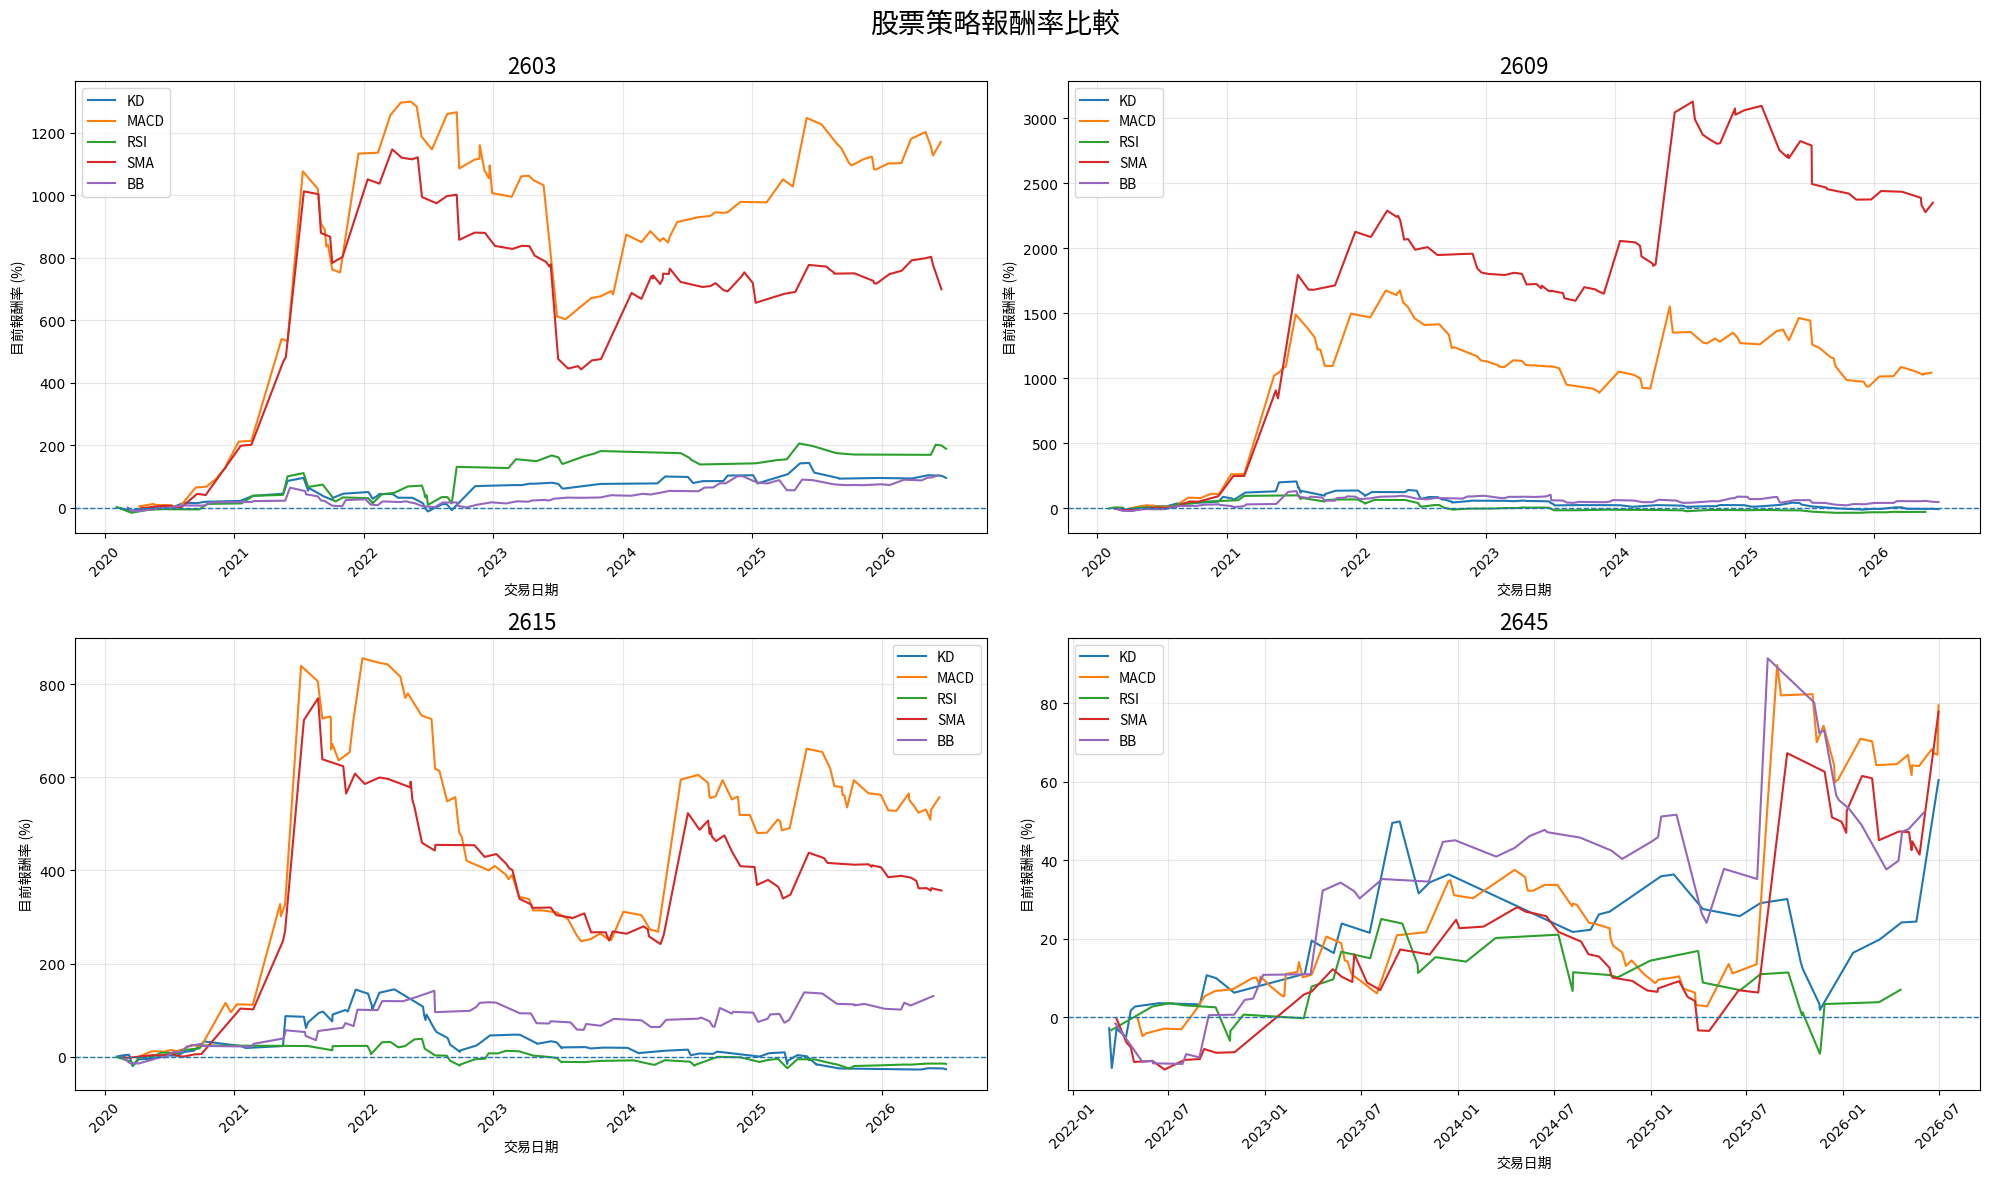

In [16]:
# 每 4 檔股票畫成一張 2×2 子圖
for start in range(0, len(stock_ids), 4):

    current_stocks = stock_ids[start:start + 4]
    fig, axes = plt.subplots(2, 2, figsize=(20, 12))
    axes = axes.flatten()

    for i, stock_id in enumerate(current_stocks):

        ax = axes[i]
        has_data = False

        for strategy, folder in strategy_folders.items():

            file_path = os.path.join(folder, f"{stock_id}_df_trades.csv")

            if not os.path.exists(file_path):
                print(f"{stock_id}：找不到 {strategy} 資料")
                continue

            df = pd.read_csv(file_path)

            if "交易日期" not in df.columns:
                print(f"{stock_id} {strategy}：缺少「交易日期」欄位")
                continue

            if "目前報酬率(%)" not in df.columns:
                print(f"{stock_id} {strategy}：缺少「目前報酬率(%)」欄位")
                continue

            df["交易日期"] = pd.to_datetime(df["交易日期"], errors="coerce")
            df["目前報酬率(%)"] = pd.to_numeric(df["目前報酬率(%)"], errors="coerce")
            df = df.dropna(subset=["交易日期", "目前報酬率(%)"]).sort_values("交易日期")

            ax.plot(df["交易日期"], df["目前報酬率(%)"], label=strategy)
            has_data = True

        if has_data:
            ax.axhline(y=0, linestyle="--", linewidth=1)
            ax.set_title(stock_id, fontproperties=font_prop, fontsize=16)
            ax.set_ylabel("目前報酬率 (%)", fontproperties=font_prop)
            ax.set_xlabel("交易日期", fontproperties=font_prop)
            ax.legend(prop=font_prop)
            ax.grid(True, alpha=0.3)
            ax.tick_params(axis="x", rotation=45)
        else:
            ax.set_visible(False)

    for j in range(len(current_stocks), 4):
        axes[j].set_visible(False)

    fig.suptitle("股票策略報酬率比較", fontproperties=font_prop, fontsize=20)
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show()